# 1. k-distance elbow

**Idea:** for every focal length, measure the distance to its k-th nearest neighbour (k = `MIN_SAMPLES`, counting the point itself, as DBSCAN does). Sort those distances. Points inside a dense group have small distances, and isolated points have large ones. The curve stays flat inside groups and bends sharply where isolated points start. The bend, the **elbow**, is a good `eps`.

**Elbow detection:** the point furthest below the straight line joining the curve's first and last points.

**Reading the plot:** the dashed red line is the suggested `eps`. Pick a different `MIN_SAMPLES` to see how the elbow moves.

**Why `MIN_SAMPLES = 20` and not 2:** most photos share their exact focal length with another photo, so with a small k the distance is 0 for most points and the elbow collapses to `eps = 0`. A larger k measures spread across a whole group rather than exact duplicates.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent  # notebooks are run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import load_focal_mm

DIRECTORY, DEPTH = r"D:\DCIM", 1
focal = load_focal_mm(DIRECTORY, DEPTH)
print(f"{len(focal)} images, focal length {focal.min():.0f}-{focal.max():.0f} mm, {len(np.unique(focal))} distinct values")


885 images, focal length 18-135 mm, 87 distinct values


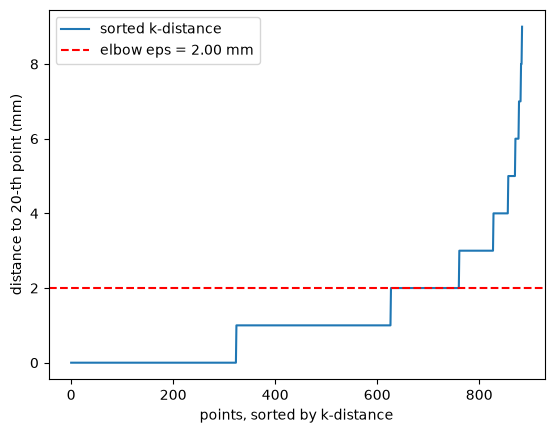

Suggested eps = 2.00 mm (MIN_SAMPLES = 20)


In [2]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 20
X = focal.reshape(-1, 1)
dists, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
kdist = np.sort(dists[:, -1])  # distance to the MIN_SAMPLES-th point, self included

line = np.linspace(kdist[0], kdist[-1], len(kdist))
elbow = int(np.argmax(line - kdist))
eps = kdist[elbow]

plt.plot(kdist, label="sorted k-distance")
plt.axhline(eps, ls="--", color="red", label=f"elbow eps = {eps:.2f} mm")
plt.xlabel("points, sorted by k-distance")
plt.ylabel(f"distance to {MIN_SAMPLES}-th point (mm)")
plt.legend()
plt.show()
print(f"Suggested eps = {eps:.2f} mm (MIN_SAMPLES = {MIN_SAMPLES})")

## What to take away
Use the suggested `eps` as the DBSCAN setting with `min_samples = MIN_SAMPLES`. If the curve has no clear bend, the focal lengths have no distinct gaps and the method gives little guidance.